# Part 3: Grids against Monte Carlo as the dimension grows

**Aim of this part**

Parts 1 and 2 priced the same option in two ways, and in one dimension the grid won easily. This part asks when that stops being true. Feynman-Kac works in any number of dimensions: an option on $d$ stocks has a price that solves a PDE in $d$ space variables and is also an expectation over $d$ correlated Brownian motions. Section 4.2 of the course notes warns that a grid method which needs $N$ points in one dimension needs $N^d$ points in $d$ dimensions, while Monte Carlo error does not depend on $d$ at all. We first measure the one dimensional comparison properly. We then derive the convergence rates of each method as a function of $d$, and finally measure them on a pricing problem with a closed form in every dimension, to find where the crossover actually happens.

In [1]:
import sys
import time
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

from pricing import black_scholes as bs
from pricing import pde, sde, high_dim
from pricing.plot_style import use_project_style, COLOURS, MARKERS, INK, GREY

use_project_style()

S0, K, r, sigma, T = 100.0, 100.0, 0.05, 0.2, 1.0
exact_call = bs.call_price(S0, K, r, sigma, T)
discount = np.exp(-r * T)
rng = np.random.default_rng(4)

**One dimension: the grid wins easily**

We time the Crank-Nicolson solver with Rannacher smoothing from Part 1 (with $N_\tau = N_x/10$) and exact sampling Monte Carlo from Part 2 on the European call, and plot the error against CPU time. For the PDE the error is the actual error at $S_0$. For Monte Carlo we plot the standard error, which Part 2 showed is a reliable estimate of the typical (root mean square) error. Timings depend on the computer, so only their rough size matters.

PDE  N_x =     50   time =   0.0004 s   error = 1.79e-01
PDE  N_x =    100   time =   0.0004 s   error = 4.36e-02
PDE  N_x =    200   time =   0.0009 s   error = 1.09e-02
PDE  N_x =    400   time =   0.0022 s   error = 2.73e-03
PDE  N_x =    800   time =   0.0041 s   error = 6.85e-04
PDE  N_x =   1600   time =   0.0120 s   error = 1.72e-04
PDE  N_x =   3200   time =   0.0297 s   error = 4.29e-05
PDE  N_x =   6400   time =   0.1083 s   error = 1.07e-05
PDE  N_x =  12800   time =   0.3703 s   error = 2.69e-06
MC   M   =     1000 time =   0.0000 s   standard error = 4.56e-01
MC   M   =    10000 time =   0.0003 s   standard error = 1.47e-01
MC   M   =   100000 time =   0.0014 s   standard error = 4.67e-02
MC   M   =  1000000 time =   0.0367 s   standard error = 1.47e-02
MC   M   = 10000000 time =   0.4248 s   standard error = 4.65e-03

PDE error against work N_x * N_tau: fitted slope -1.00
Monte Carlo paths needed for an error of 2.7e-06: 3.0e+13, about 15 days


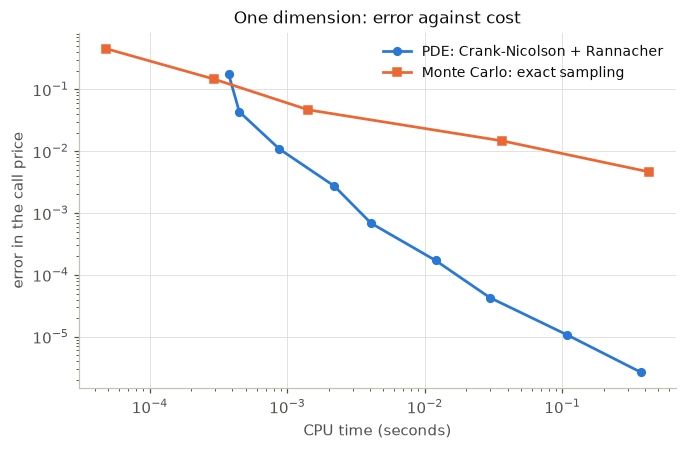

In [2]:
def best_time(function, repeats=3):
    # Smallest wall clock time over a few repeats, to reduce timing noise.
    times = []
    for i in range(repeats):
        start = time.perf_counter()
        result = function()
        times.append(time.perf_counter() - start)
    return min(times), result


n_x_values = np.array([50, 100, 200, 400, 800, 1600, 3200, 6400, 12800])
pde_times, pde_errors, pde_work = [], [], []
for n_x in n_x_values:
    n_tau = n_x // 10
    elapsed, (S, V) = best_time(lambda: pde.price_heat_grid("call", K, r, sigma, T, 2.0, n_x, n_tau, 0.5, n_rannacher=2))
    pde_times.append(elapsed)
    pde_errors.append(abs(V[n_x // 2] - exact_call))
    pde_work.append(n_x * n_tau)
pde_times, pde_errors, pde_work = np.array(pde_times), np.array(pde_errors), np.array(pde_work)

M_values = np.array([10**3, 10**4, 10**5, 10**6, 10**7])
mc_times, mc_errors = [], []
for M in M_values:
    def run_mc():
        S_T = sde.sample_exact_terminal(S0, r, sigma, T, M, rng)
        return sde.mc_estimate(discount * np.maximum(S_T - K, 0.0))
    elapsed, (estimate, std_error) = best_time(run_mc)
    mc_times.append(elapsed)
    mc_errors.append(std_error)
mc_times, mc_errors = np.array(mc_times), np.array(mc_errors)

for n_x, t, e in zip(n_x_values, pde_times, pde_errors):
    print(f"PDE  N_x = {n_x:6d}   time = {t:8.4f} s   error = {e:.2e}")
for M, t, e in zip(M_values, mc_times, mc_errors):
    print(f"MC   M   = {M:8d} time = {t:8.4f} s   standard error = {e:.2e}")

work_slope = np.polyfit(np.log(pde_work), np.log(pde_errors), 1)[0]
print()
print(f"PDE error against work N_x * N_tau: fitted slope {work_slope:.2f}")

# How long would Monte Carlo need to match the finest PDE grid? Time grows like M, and M like 1/error^2.
time_per_path = mc_times[-1] / M_values[-1]
s = mc_errors[-1] * np.sqrt(M_values[-1])
M_needed = (s / pde_errors[-1]) ** 2
print(f"Monte Carlo paths needed for an error of {pde_errors[-1]:.1e}: {M_needed:.1e}, about {M_needed * time_per_path / 86400:.0f} days")

fig, ax = plt.subplots()
ax.loglog(pde_times, pde_errors, "o-", color=COLOURS[0], label="PDE: Crank-Nicolson + Rannacher")
ax.loglog(mc_times, mc_errors, "s-", color=COLOURS[1], label="Monte Carlo: exact sampling")
ax.set_xlabel("CPU time (seconds)")
ax.set_ylabel("error in the call price")
ax.set_title("One dimension: error against cost")
ax.legend()
fig.savefig("../figures/03_one_dimension_cost.png")
plt.show()

The PDE reaches an error of a few times $10^{-6}$ in under half a second, while Monte Carlo is only at about $5 \times 10^{-3}$ after the same time. Matching the PDE's accuracy by brute force Monte Carlo would take around two and a half weeks of computing. The fitted slope of $-1$ for the PDE error against the work $N_xN_\tau$ is what we expect: the error is $O(N_x^{-2})$ and the work is $N_x \cdot N_x/10 \propto N_x^2$. This slope is the input to the next section.

**Where the curse of dimensionality comes from**

Suppose a grid method has error $O(h^p)$ with $n$ points per axis, so $h \propto 1/n$ and the error is $\varepsilon \propto n^{-p}$. In $d$ dimensions a tensor product grid has $W = n^d$ points, so in terms of the total work

$$\varepsilon \propto n^{-p} = W^{-p/d}.$$

For a second order method ($p = 2$) the error falls like $W^{-2/d}$. Monte Carlo has $\varepsilon \propto W^{-1/2}$ in every dimension, because the standard error $s/\sqrt{M}$ does not involve $d$ (Glasserman 2004, Section 1.1). The grid exponent is steeper than Monte Carlo's when $2/d > 1/2$, that is for $d < 4$, and shallower for $d > 4$.

A PDE solver also has to step in time. With Crank-Nicolson and $\Delta\tau \propto \Delta x$, as in the previous section, the number of time steps is proportional to $n$, so $W = n^{d+1}$ and $\varepsilon \propto W^{-2/(d+1)}$, which loses to Monte Carlo for $d > 3$. The explicit scheme is worse still. Its stability condition forces $\Delta\tau \propto \Delta x^2$, so $W = n^{d+2}$, $\varepsilon \propto W^{-2/(d+2)}$, and it loses for $d > 2$. So the stability analysis of Part 1 effectively costs the explicit scheme a whole dimension. These exponents only say which method wins for sufficiently small $\varepsilon$. The constants decide where the crossover happens at a practical accuracy, which is what we measure below.

In [3]:
print("  d   quadrature grid   PDE, Crank-Nicolson   PDE, explicit   Monte Carlo")
for d in range(1, 9):
    print(f"{d:3d}       {-2 / d:6.3f}              {-2 / (d + 1):6.3f}            {-2 / (d + 2):6.3f}        -0.500")

  d   quadrature grid   PDE, Crank-Nicolson   PDE, explicit   Monte Carlo
  1       -2.000              -1.000            -0.667        -0.500
  2       -1.000              -0.667            -0.500        -0.500
  3       -0.667              -0.500            -0.400        -0.500
  4       -0.500              -0.400            -0.333        -0.500
  5       -0.400              -0.333            -0.286        -0.500
  6       -0.333              -0.286            -0.250        -0.500
  7       -0.286              -0.250            -0.222        -0.500
  8       -0.250              -0.222            -0.200        -0.500


**A warm up: the volume of the unit ball**

Exercise R4.2 estimates the volume of the unit ball in $d$ dimensions by sampling uniform points in the cube $[-1,1]^d$ and counting the fraction $p$ that land inside. The estimate is $2^d p$ and its standard error is $2^d\sqrt{p(1-p)/M}$, so the relative standard error is

$$\frac{\text{standard error}}{\text{volume}} = \sqrt{\frac{1-p}{pM}}.$$

The rate $M^{-1/2}$ is the same in every dimension, but the constant depends on $p = V_d/2^d$, the fraction of the cube taken up by the ball, and this fraction collapses as $d$ grows. The cell below estimates the volume for $d = 1$ to $12$ with $10^6$ points each.

d =  1   estimate = 2.0000   exact = 2.0000   relative standard error = 0.00e+00   p = 1.00e+00
d =  2   estimate = 3.1410   exact = 3.1416   relative standard error = 5.23e-04   p = 7.85e-01
d =  3   estimate = 4.1904   exact = 4.1888   relative standard error = 9.54e-04   p = 5.24e-01
d =  4   estimate = 4.9422   exact = 4.9348   relative standard error = 1.50e-03   p = 3.08e-01
d =  5   estimate = 5.2703   exact = 5.2638   relative standard error = 2.25e-03   p = 1.64e-01


d =  6   estimate = 5.1640   exact = 5.1677   relative standard error = 3.37e-03   p = 8.07e-02
d =  7   estimate = 4.7346   exact = 4.7248   relative standard error = 5.11e-03   p = 3.69e-02
d =  8   estimate = 4.0791   exact = 4.0587   relative standard error = 7.90e-03   p = 1.59e-02


d =  9   estimate = 3.2507   exact = 3.2985   relative standard error = 1.23e-02   p = 6.44e-03
d = 10   estimate = 2.4852   exact = 2.5502   relative standard error = 1.98e-02   p = 2.49e-03


d = 11   estimate = 1.8575   exact = 1.8841   relative standard error = 3.27e-02   p = 9.20e-04
d = 12   estimate = 1.1715   exact = 1.3353   relative standard error = 5.19e-02   p = 3.26e-04


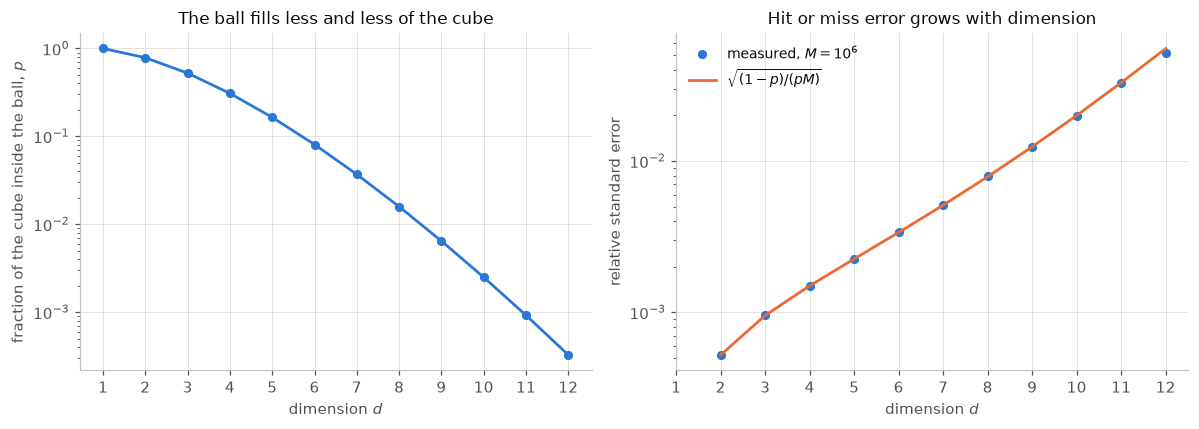

In [4]:
dims = np.arange(1, 13)
M = 1_000_000
volumes, rel_errors, fractions = [], [], []
for d in dims:
    volume, std_error = high_dim.ball_volume_mc(d, M, rng)
    exact = high_dim.ball_volume_exact(d)
    p = exact / 2.0**d
    volumes.append(volume)
    rel_errors.append(std_error / exact)
    fractions.append(p)
    print(f"d = {d:2d}   estimate = {volume:.4f}   exact = {exact:.4f}   relative standard error = {std_error / exact:.2e}   p = {p:.2e}")
fractions, rel_errors = np.array(fractions), np.array(rel_errors)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogy(dims, fractions, "o-", color=COLOURS[0])
axes[0].set_xlabel("dimension $d$")
axes[0].set_ylabel("fraction of the cube inside the ball, $p$")
axes[0].set_title("The ball fills less and less of the cube")

axes[1].semilogy(dims[1:], rel_errors[1:], "o", color=COLOURS[0], label="measured, $M = 10^6$")
axes[1].semilogy(dims[1:], np.sqrt((1 - fractions[1:]) / (fractions[1:] * M)), "-", color=COLOURS[1], label=r"$\sqrt{(1-p)/(pM)}$")
axes[1].set_xlabel("dimension $d$")
axes[1].set_ylabel("relative standard error")
axes[1].set_title("Hit or miss error grows with dimension")
axes[1].legend()
for ax in axes:
    ax.set_xticks(dims)
fig.tight_layout()
fig.savefig("../figures/03_ball_volume.png")
plt.show()

The relative error grows by a factor of about 100 between $d = 2$ and $d = 12$, exactly as the formula predicts, because only about 3 in 10000 points land inside the 12 dimensional ball. For $d = 1$ the ball is the whole interval, so $p = 1$ and the error is zero. This is an important caveat to the usual slogan. Monte Carlo has a dimension free convergence rate, but not a dimension free cost, since the variance constant can depend badly on $d$. The fix is to sample more cleverly, for example from a distribution concentrated where the integrand lives (importance sampling). The same issue appears in pricing whenever the payoff is a rare event, such as a deep out of the money option.

**A pricing problem in $d$ dimensions**

To compare grids and Monte Carlo on a real pricing problem with an exact answer, we use a call on the geometric average of $d$ independent stocks, each with the same parameters as before. If $z_1, \dots, z_d$ are the independent standard normals driving the stocks, the geometric average at expiry is

$$G(T) = \left(\prod_{i=1}^d S_i(T)\right)^{1/d} = S_0\exp\left(\left(r - \tfrac{1}{2}\sigma^2\right)T + \sigma\sqrt{T}\,\frac{z_1 + \dots + z_d}{d}\right),$$

and the price is the $d$ dimensional integral

$$V = e^{-rT}\int_{\mathbb{R}^d}\max\left(G(T) - K, 0\right)\varphi(z_1)\cdots\varphi(z_d)\,dz_1\cdots dz_d,$$

where $\varphi$ is the standard normal density. Because $\ln G(T)$ is normal, $V$ has a Black-Scholes style closed form (`geometric_basket_call_price`), so we can measure true errors in every dimension. The grid method is the tensor product trapezoid rule: each $z_i$ runs over $n$ equally spaced points in $[-6, 6]$, giving $n^d$ points in total. This is the quadrature analogue of a PDE grid, without the time stepping. Monte Carlo just samples the $z_i$.

The integrand actually only depends on $z_1 + \dots + z_d$, so we could reduce the problem to one dimension using the symmetry ideas of Section 4.2.1. We deliberately do not, because the geometric basket stands in for products like the arithmetic basket, where no such reduction exists.

d = 1   exact price = 10.4506   fitted grid slope = -1.93 (theory -2.00)   payoff std s_d = 14.70


d = 2   exact price = 7.6297   fitted grid slope = -1.07 (theory -1.00)   payoff std s_d = 10.14
d = 3   exact price = 6.4603   fitted grid slope = -0.84 (theory -0.67)   payoff std s_d = 8.27


d = 4   exact price = 5.7888   fitted grid slope = -0.72 (theory -0.50)   payoff std s_d = 7.19


d = 5   exact price = 5.3429   fitted grid slope = -0.61 (theory -0.40)   payoff std s_d = 6.48


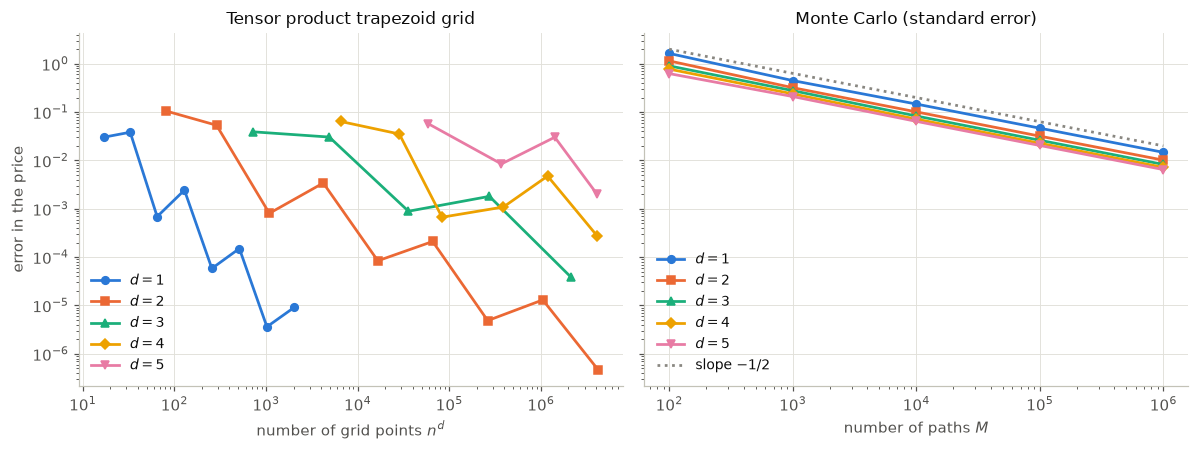

In [5]:
grid_n = {1: [17, 33, 65, 129, 257, 513, 1025, 2049],
          2: [9, 17, 33, 65, 129, 257, 513, 1025, 2049],
          3: [9, 17, 33, 65, 129],
          4: [9, 13, 17, 25, 33, 45],
          5: [9, 13, 17, 21]}
mc_M = np.array([10**2, 10**3, 10**4, 10**5, 10**6])

grid_points, grid_errors, mc_std_errors, payoff_std, fits = {}, {}, {}, {}, {}
for d in range(1, 6):
    exact = bs.geometric_basket_call_price(np.full(d, S0), K, r, np.full(d, sigma), T, np.eye(d))
    points, errors = [], []
    for n in grid_n[d]:
        price = high_dim.geometric_basket_grid(S0, K, r, sigma, T, d, n)
        points.append(n**d)
        errors.append(max(abs(price - exact), 1e-12))  # guard against an error of exactly zero on a log plot
    grid_points[d], grid_errors[d] = np.array(points), np.array(errors)
    fits[d] = np.polyfit(np.log(grid_points[d]), np.log(grid_errors[d]), 1)  # log error = slope * log W + intercept

    ses = []
    for M in mc_M:
        estimate, std_error = high_dim.geometric_basket_mc(S0, K, r, sigma, T, d, M, rng)
        ses.append(std_error)
    mc_std_errors[d] = np.array(ses)
    payoff_std[d] = ses[-1] * np.sqrt(mc_M[-1])  # standard deviation of one discounted payoff
    print(f"d = {d}   exact price = {exact:.4f}   fitted grid slope = {fits[d][0]:5.2f} (theory {-2 / d:5.2f})   payoff std s_d = {payoff_std[d]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for d in range(1, 6):
    axes[0].loglog(grid_points[d], grid_errors[d], marker=MARKERS[d - 1], color=COLOURS[d - 1], label=f"$d = {d}$")
    axes[1].loglog(mc_M, mc_std_errors[d], marker=MARKERS[d - 1], color=COLOURS[d - 1], label=f"$d = {d}$")
axes[0].set_title("Tensor product trapezoid grid")
axes[0].set_xlabel("number of grid points $n^d$")
axes[0].set_ylabel("error in the price")
axes[1].set_title("Monte Carlo (standard error)")
axes[1].set_xlabel("number of paths $M$")
axes[1].loglog(mc_M, 2.0 * (mc_M / mc_M[0]) ** -0.5, ":", color=GREY, label="slope $-1/2$")
axes[0].legend()
axes[1].legend()
fig.tight_layout()
fig.savefig("../figures/03_grid_vs_mc_by_dimension.png")
plt.show()

The two panels show the curse of dimensionality directly. The Monte Carlo lines all have slope $-\frac{1}{2}$ and sit close together. They even move slightly down as $d$ grows, because the average of $d$ independent stocks is less volatile than one stock (its volatility is $\sigma/\sqrt{d}$), so the payoff variance falls. The grid lines get flatter and move to the right as $d$ increases. The fitted slopes are close to $-2/d$ for $d = 1$ and $2$, and somewhat steeper than $-2/d$ for $d = 3, 4, 5$. In those dimensions we can only afford coarse grids before running out of memory, so the fits are pre-asymptotic. The grid errors are also irregular, jumping up and down by a factor of about 4 between neighbouring grids. This is the integration over a discontinuity issue from R1.3: the payoff has a kink along the plane $z_1 + \dots + z_d = \text{const}$, and the trapezoid error depends on exactly where that kink falls relative to the grid points. The overall $h^2$ trend still holds.

**Turning the measurements into a crossover**

From the fits we can read off how many function evaluations each method needs to reach a target error $\varepsilon$. For the grid we invert the fitted line, $W = \exp\left((\ln\varepsilon - b_d)/a_d\right)$, where $a_d$ is the fitted slope and $b_d$ the intercept. For Monte Carlo we need $s_d/\sqrt{M} = \varepsilon$, so $M = (s_d/\varepsilon)^2$. We also add a simple model of a full PDE solver in $d$ dimensions: we assume it needs the same resolution per axis as our one dimensional Crank-Nicolson solver, whose error was $C/N_x^2$ with $N_\tau = N_x/10$. Then $N_x = \sqrt{C/\varepsilon}$ and $W = N_x^d \cdot N_x/10$. This last curve is an extrapolation from $d = 1$, not a measurement.

One dimensional PDE error constant C = 440

Target error 1e-02: evaluations needed
  d = 1   quadrature grid  3.44e+01   PDE model  4.40e+03   Monte Carlo  2.16e+06   cheaper of grid and MC: grid
  d = 2   quadrature grid  5.89e+02   PDE model  9.23e+05   Monte Carlo  1.03e+06   cheaper of grid and MC: grid
  d = 3   quadrature grid  6.69e+03   PDE model  1.94e+08   Monte Carlo  6.84e+05   cheaper of grid and MC: grid
  d = 4   quadrature grid  4.27e+04   PDE model  4.06e+10   Monte Carlo  5.18e+05   cheaper of grid and MC: grid
  d = 5   quadrature grid  9.40e+05   PDE model  8.52e+12   Monte Carlo  4.19e+05   cheaper of grid and MC: Monte Carlo

Target error 1e-03: evaluations needed
  d = 1   quadrature grid  1.13e+02   PDE model  4.40e+04   Monte Carlo  2.16e+08   cheaper of grid and MC: grid
  d = 2   quadrature grid  5.10e+03   PDE model  2.92e+07   Monte Carlo  1.03e+08   cheaper of grid and MC: grid
  d = 3   quadrature grid  1.05e+05   PDE model  1.94e+10   Monte Carlo  6.84e+

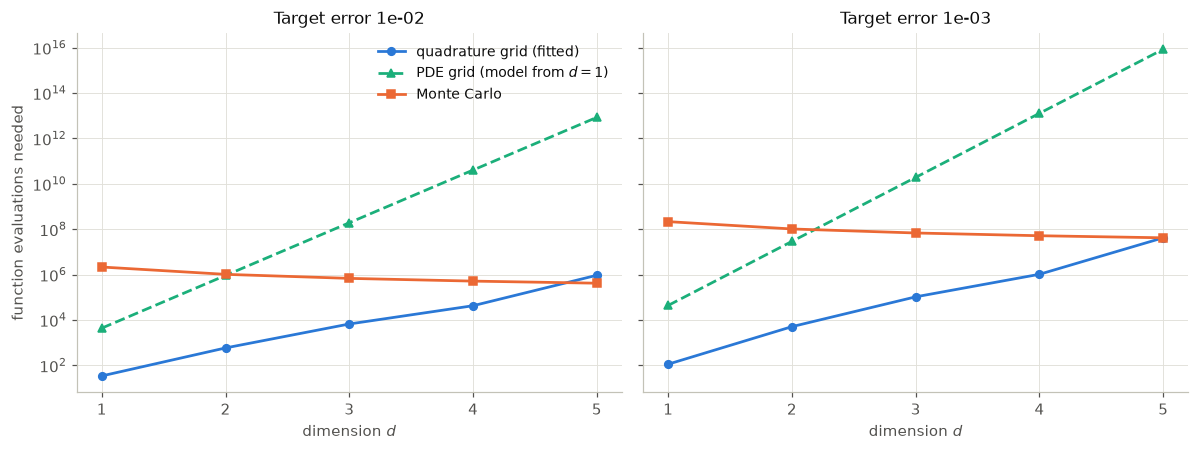

In [6]:
C = pde_errors[-1] * n_x_values[-1] ** 2  # one dimensional PDE error constant, error = C / N_x^2
print(f"One dimensional PDE error constant C = {C:.0f}")
print()

dims = np.arange(1, 6)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, eps in zip(axes, [1e-2, 1e-3]):
    W_grid = np.array([np.exp((np.log(eps) - fits[d][1]) / fits[d][0]) for d in dims])
    W_mc = np.array([(payoff_std[d] / eps) ** 2 for d in dims])
    n_pde = np.sqrt(C / eps)
    W_pde = n_pde**dims * n_pde / 10

    print(f"Target error {eps:.0e}: evaluations needed")
    for i, d in enumerate(dims):
        winner = "grid" if W_grid[i] < W_mc[i] else "Monte Carlo"
        print(f"  d = {d}   quadrature grid {W_grid[i]:9.2e}   PDE model {W_pde[i]:9.2e}   Monte Carlo {W_mc[i]:9.2e}   cheaper of grid and MC: {winner}")
    print()

    ax.semilogy(dims, W_grid, "o-", color=COLOURS[0], label="quadrature grid (fitted)")
    ax.semilogy(dims, W_pde, "^--", color=COLOURS[2], label="PDE grid (model from $d = 1$)")
    ax.semilogy(dims, W_mc, "s-", color=COLOURS[1], label="Monte Carlo")
    ax.set_xticks(dims)
    ax.set_xlabel("dimension $d$")
    ax.set_title(f"Target error {eps:.0e}")
axes[0].set_ylabel("function evaluations needed")
axes[0].legend()
fig.tight_layout()
fig.savefig("../figures/03_crossover.png")
plt.show()

For a target error of $10^{-2}$ the quadrature grid is cheaper up to $d = 4$, and Monte Carlo is cheaper at $d = 5$. For $10^{-3}$ the two are roughly level at $d = 5$. This is a little later than the asymptotic prediction of $d = 4$. The main reason is that on the coarse grids we can afford in $d = 3, 4, 5$ the grid converges faster than its asymptotic rate, which flatters the grid. Working the other way, the falling payoff variance flatters Monte Carlo. The PDE model, which also pays for time stepping, is roughly level with Monte Carlo at $d = 2$ and loses clearly from $d = 3$, as the exponent $-2/(d+1)$ predicts. At $d = 3$ and a target of $10^{-2}$ it needs about $2 \times 10^8$ evaluations against Monte Carlo's $7 \times 10^5$. A function evaluation costs roughly the same in each method, a few exponentials and additions, so these counts are a fair proxy for CPU time.

**Discussion**

The comparison has a clear shape. In one dimension the grid is better by many orders of magnitude, because second order convergence beats $M^{-1/2}$ convergence easily. The grid's advantage is eroded at a rate set by its convergence exponent per unit of work, $-p/d$ for quadrature and $-p/(d+1)$ for a time stepping PDE, while Monte Carlo keeps $-\frac{1}{2}$. With second order methods the crossover is at about four dimensions for quadrature and three for a Crank-Nicolson PDE, and our measurements on the geometric basket put it at four to five dimensions for quadrature at practical accuracies. Stability matters here too: the explicit scheme's $\Delta\tau \propto \Delta x^2$ restriction moves its crossover down to two dimensions.

These conclusions have limits. Our test problem is unusually kind to both methods: the payoff variance falls with $d$, and the integrand secretly depends on only one combination of the variables. Better grid methods exist, such as sparse grids and alternating direction implicit schemes, which push the grid crossover to higher dimensions, and better sampling methods exist, such as quasi-Monte Carlo and variance reduction, which push it lower. The ball volume example shows that a dimension free rate can still hide a constant that grows quickly with $d$. Still, the basic message of Section 4.2 holds up: beyond a handful of dimensions grids become hopeless, and Monte Carlo is the only general tool left. Part 4 takes that seriously and prices a 20 stock basket.